# MiDaS — монокуляр гүний тооцоолол: загвар ба inference

**CS322 бие даалт, 11-р баг.** Энэ хэсгийг Б.Төгөлдөр (B242270047) хийсэн.

Энэ notebook-оор дараах ажлуудыг хийнэ:
1. Орчин бэлдэх (Colab эсвэл локал).
2. `torch.hub`-аар `DPT_Large`, `DPT_Hybrid`, `MiDaS_small` гэсэн гурван загварыг ачаална.
3. Нэг зурагнаас depth map гаргана (`src/depth.py`).
4. Гурван загварыг бүх туршилтын зураг дээр ажиллуулж, хурд болон чанарыг харьцуулна.

> MiDaS-ийн гаралт нь **relative inverse depth** юм. Утга нь том бол ойрхон, жижиг бол хол гэсэн үг. Метрээр хэмжсэн бодит зай биш тул хоёр зургийн утгыг шууд харьцуулах боломжгүй.

## 1. Орчин бэлдэх
Colab дээр репог clone хийнэ. Локал дээр ажиллаж байгаа бол энэ нүд зөвхөн root фолдер руу шилжинэ.

In [1]:
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("Computeriin-haraa"):
        !git clone -q https://github.com/Tugu8/Computeriin-haraa.git
    %cd Computeriin-haraa
    !pip install -q timm
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
print("Ажлын фолдер:", os.getcwd())

Ажлын фолдер: C:\Users\User\OneDrive\Desktop\Computeriin_Haraa\Bie_Daalt


In [2]:
import time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from src.depth import (MODEL_TYPES, load_model, predict_depth, read_image,
                       depth_to_color, normalize_depth, benchmark, count_params, get_device)

device = get_device()
print("torch", torch.__version__, "| төхөөрөмж:", device)

torch 2.15.0+cpu | төхөөрөмж: cpu


## 2. Загварууд

| Загвар | Encoder | Оролтын хэмжээ | Онцлог |
|---|---|---|---|
| `DPT_Large` | ViT-L/16 | 384 | Хамгийн нарийвчлалтай, хамгийн удаан |
| `DPT_Hybrid` | ViT-Hybrid (ResNet-50 + ViT-B) | 384 | Чанар, хурдны дундаж |
| `MiDaS_small` | EfficientNet-Lite3 | 256 | Хөнгөн, утас болон бодит хугацааны хэрэглээнд тохиромжтой |

Загвар бүрийг хамгийн эхний удаа ажиллуулахад жинг нь интернэтээс татна. `DPT_Large` нь ойролцоогоор 1.3 GB.

## 3. Нэг зураг дээр турших

Using cache found in C:\Users\User/.cache\torch\hub\intel-isl_MiDaS_master


C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\timm\models\_factory.py:230: UserWarning: Mapping deprecated model name vit_base_resnet50_384 to current vit_base_r50_s16_384.orig_in21k_ft_in1k.
  model = create_fn(


Using cache found in C:\Users\User/.cache\torch\hub\intel-isl_MiDaS_master


Хугацаа: 4.81 с | хэмжээ: (853, 1280) | утга: [-169.4, 3102.1]


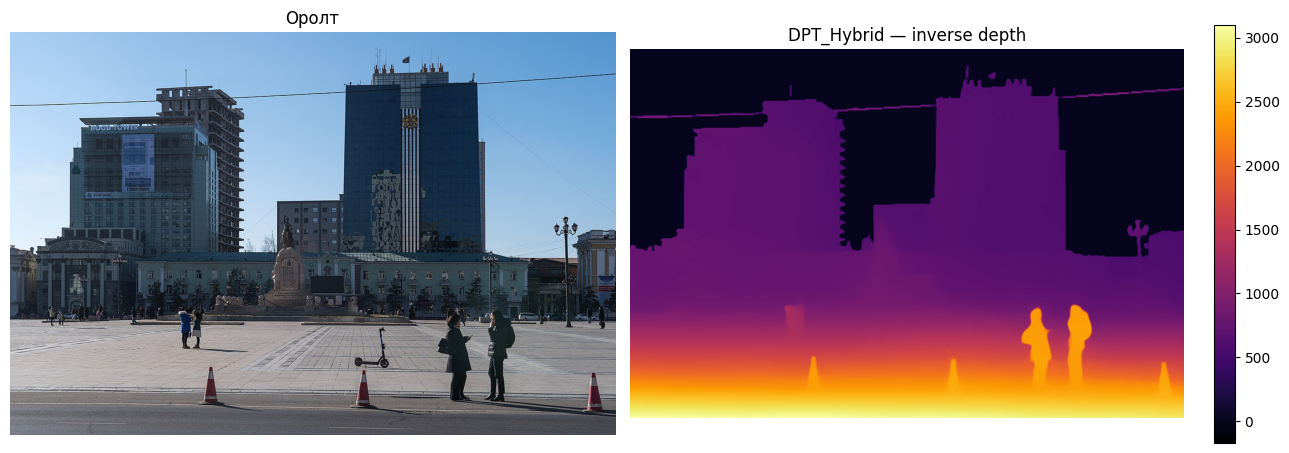

In [3]:
img = read_image("data/images/ulaanbaatar.jpg")
model, transform, device = load_model("DPT_Hybrid")

t0 = time.perf_counter()
depth = predict_depth(model, transform, img, device)
print(f"Хугацаа: {time.perf_counter() - t0:.2f} с | хэмжээ: {depth.shape} | утга: [{depth.min():.1f}, {depth.max():.1f}]")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].imshow(img); ax[0].set_title("Оролт")
im = ax[1].imshow(depth, cmap="inferno"); ax[1].set_title("DPT_Hybrid — inverse depth")
plt.colorbar(im, ax=ax[1], fraction=0.035)
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

`predict_depth` дотор хийгддэг алхмууд:
1. `transform` нь зургийг загварын оролтын хэмжээ (384 эсвэл 256) рүү, 32-т хуваагддаг тоогоор харьцааг хадгалан багасгаж, ImageNet-ийн дундаж болон стандарт хазайлтаар нормчилно.
2. Загвар `(1, h, w)` хэмжээтэй inverse depth гаргана.
3. `bicubic` interpolation-оор эх зургийн хэмжээ рүү буцааж томруулна. Ингэснээр depth map эх зурагтай пиксел бүрээр давхцана.

## 4. Гурван загварыг бүх зураг дээр ажиллуулах

In [4]:
paths = sorted(p for p in Path("data/images").iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
images = {p.stem: read_image(p) for p in paths}
print(len(images), "зураг:", list(images))

preds, speed = {}, []
for m in MODEL_TYPES:
    model, transform, device = load_model(m)
    for name, im in images.items():
        preds[(m, name)] = predict_depth(model, transform, im, device)
    mean, std = benchmark(model, transform, images["ulaanbaatar"], device, runs=3)
    speed.append((m, count_params(model) / 1e6, mean, std))
    print(f"{m:12s} {count_params(model)/1e6:6.1f}M параметр  {mean:6.3f} ± {std:.3f} с/зураг")
    del model

6 зураг: ['corridor', 'person', 'road', 'room', 'street', 'ulaanbaatar']


Using cache found in C:\Users\User/.cache\torch\hub\intel-isl_MiDaS_master


Using cache found in C:\Users\User/.cache\torch\hub\intel-isl_MiDaS_master


DPT_Large     344.1M параметр   9.531 ± 0.390 с/зураг


Using cache found in C:\Users\User/.cache\torch\hub\intel-isl_MiDaS_master


Using cache found in C:\Users\User/.cache\torch\hub\intel-isl_MiDaS_master


... (3 outputs left out)

Loading weights:  None


Using cache found in C:\Users\User/.cache\torch\hub\rwightman_gen-efficientnet-pytorch_master


Using cache found in C:\Users\User/.cache\torch\hub\intel-isl_MiDaS_master


MiDaS_small    21.3M параметр   0.237 ± 0.029 с/зураг


### 4.1 Хурдны харьцуулалт

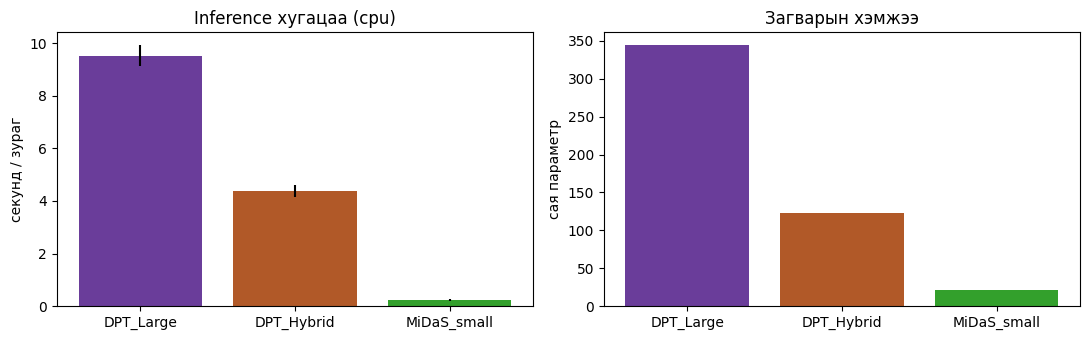

In [5]:
names = [s[0] for s in speed]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].bar(names, [s[2] for s in speed], yerr=[s[3] for s in speed], color=["#6a3d9a", "#b15928", "#33a02c"])
ax[0].set_ylabel("секунд / зураг"); ax[0].set_title(f"Inference хугацаа ({device.type})")
ax[1].bar(names, [s[1] for s in speed], color=["#6a3d9a", "#b15928", "#33a02c"])
ax[1].set_ylabel("сая параметр"); ax[1].set_title("Загварын хэмжээ")
plt.tight_layout(); plt.show()

### 4.2 Чанарын харьцуулалт

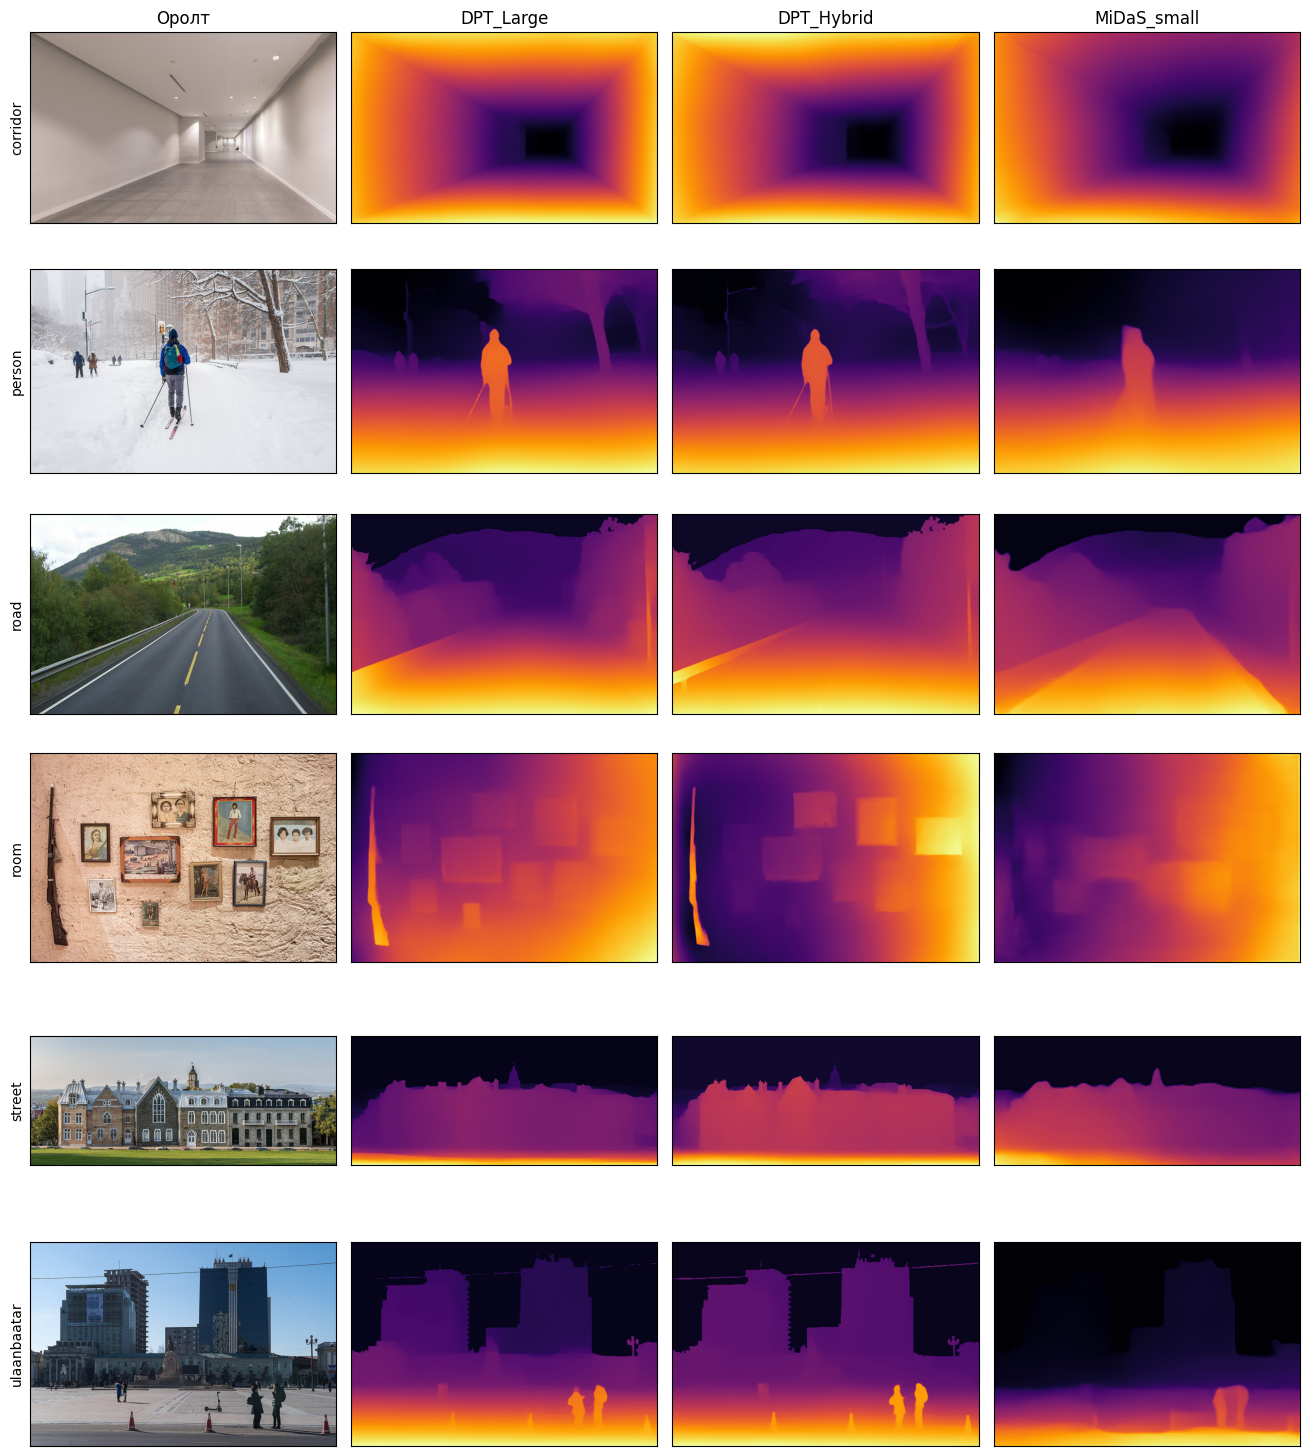

In [6]:
cols = len(MODEL_TYPES) + 1
fig, axes = plt.subplots(len(images), cols, figsize=(3.3 * cols, 2.5 * len(images)))
for r, (name, im) in enumerate(images.items()):
    axes[r, 0].imshow(im); axes[r, 0].set_ylabel(name)
    for c, m in enumerate(MODEL_TYPES, 1):
        axes[r, c].imshow(depth_to_color(preds[(m, name)]))
        if r == 0: axes[r, c].set_title(m)
    if r == 0: axes[r, 0].set_title("Оролт")
for a in axes.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

### 4.3 Загварууд хоорондоо хэр төстэй вэ?
MiDaS-ийн гаралтын масштаб зураг бүрт өөр байдаг. Иймээс depth map-уудыг шууд хасаж харьцуулах боломжгүй. Үүний оронд Spearman-ы эрэмбийн корреляци ашиглана. Энэ үзүүлэлт нь "аль пиксел нөгөөгөөсөө ойр вэ" гэсэн дарааллыг хоёр загвар хэр адилхан гаргаж байгааг харуулна. `DPT_Large`-ийг лавлагаа болгон авав.

In [7]:
from scipy.stats import spearmanr
print(f"{'зураг':12s} {'Hybrid vs Large':>16s} {'small vs Large':>16s}")
for name in images:
    ref = preds[("DPT_Large", name)][::4, ::4].ravel()
    h = spearmanr(ref, preds[("DPT_Hybrid", name)][::4, ::4].ravel())[0]
    s = spearmanr(ref, preds[("MiDaS_small", name)][::4, ::4].ravel())[0]
    print(f"{name:12s} {h:16.3f} {s:16.3f}")

зураг         Hybrid vs Large   small vs Large
corridor                0.981            0.771
person                  0.995            0.957
road                    0.995            0.962
room                    0.665            0.777
street                  0.939            0.851


ulaanbaatar             0.976            0.945


## 5. Өөрийн зураг дээр турших (Colab)
Доорх нүдийг ажиллуулаад зураг upload хийнэ үү. Энэ нүдэд хурдан ажилладаг `MiDaS_small` загварыг ашиглана.

In [8]:
if "google.colab" in sys.modules:
    from google.colab import files
    up = files.upload()
    model, transform, device = load_model("MiDaS_small")
    for fname in up:
        im = read_image(fname)
        d = predict_depth(model, transform, im, device)
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))
        ax[0].imshow(im); ax[1].imshow(d, cmap="inferno")
        for a in ax: a.axis("off")
        plt.show()
else:
    print("Локал дээр: python -m src.run_inference --images <фолдер>")

Локал дээр: python -m src.run_inference --images <фолдер>


## 6. Дүгнэлт (загвар ба inference хэсэг)

- Гурван загвар бүгд хүн, шон, барилгын хүрээ зэрэг объектуудыг арын фоноос ялгаж чадсан. Мөн коридор, зам дээрх перспективийн гүнийг зөв гаргасан.
- `DPT_Large` болон `DPT_Hybrid` загваруудын объектын ирмэг илүү тод, нарийн биетүүд (цанын саваа, цахилгааны утас) илүү сайн харагдаж байна. Хоёр загварын үр дүн бараг адилхан гарсан.
- `MiDaS_small` загварын ирмэг бүдэг, жижиг нарийн зүйлс алга болсон. Гэхдээ ерөнхий бүтэц зөв бөгөөд CPU дээр DPT_Large-аас 40–60 дахин хурдан ажилласан.
- Хана руу шууд харсан хавтгай зураг (`room`) дээр загварууд бие биетэйгээ хамгийн их зөрсөн (Spearman 0.67). Коридорын зураг дээр ч `MiDaS_small` загвар бусдаасаа их зөрсөн (0.77). Хавтгай гадаргад гүний мэдээлэл бага байдаг тул загвар зүүн-баруун талын гэрэлтүүлэгт тулгуурлан "налуу" байгаа мэтээр буруу дүгнэсэн байж магадгүй.
- Чанар чухал бол `DPT_Hybrid` загварыг сонгох нь хамгийн тохиромжтой. Хурд чухал бол (видео, вэбкам) `MiDaS_small` загварыг сонгоно.